In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
units = pd.read_csv('units_L234.csv').copy()

In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

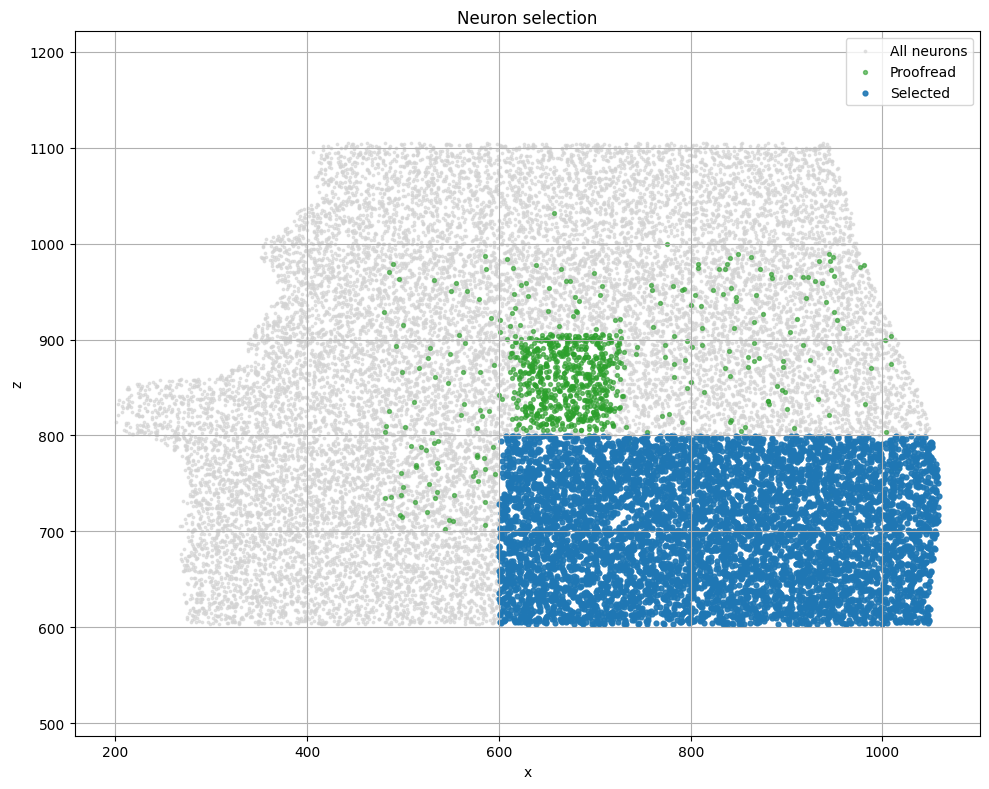

In [4]:
units_cleaned = clean_dataset(units)

selected_mask = (units_cleaned["pt_position_z"] < 800) & (units_cleaned["pt_position_x"] > 600)

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    units.loc[selected_mask, "pt_position_x"],
    units.loc[selected_mask, "pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [5]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [6]:
E_L23 = units_cleaned[mask_exc & mask_l23 & selected_mask].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [7]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [8]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [9]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [10]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [11]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z'
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [12]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    id_to_pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
    ]

    positions = id_to_pos.loc[
        np.array(all_ids)
    ].values.astype(np.float32)

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values

    positions = (positions - positions.mean(axis=0, keepdims=True)) / (positions.std(axis=0, keepdims=True)+ 1e-8)

    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = [
    "pre_pt_position_x",
    "pre_pt_position_y",
    "pre_pt_position_z",
    "post_pt_position_x",
    "post_pt_position_y",
    "post_pt_position_z",
    ]

    print(df)

    X = df[features].to_numpy(dtype=np.float32)
    y = df['label'].values

    return X, y, features, pre_idx, post_idx, positions

In [13]:
path, pre, post = pathways[0]
X, y, features, pre_idx, post_idx, positions = build_dataset(pre, post, synapses, metric=['Euclidean'])

71408
11611056
              pre_pt_root_id     post_pt_root_id      size  pre_pt_position_x  \
0         864691134884804602  864691136267238900  1.048946         793.389404   
1         864691134885076730  864691135719709489  0.017885         890.064514   
2         864691134885076730  864691135841733859  0.071092         890.064514   
3         864691134885518074  864691136700131694  0.041582         699.402466   
4         864691134885576442  864691136811834227  1.107519         927.851685   
...                      ...                 ...       ...                ...   
11682459  864691136238038799  864691136663328222  0.000000         708.155273   
11682460  864691136238038799  864691135644599279  0.000000         708.155273   
11682461  864691136238038799  864691135468547212  0.000000         708.155273   
11682462  864691136238038799  864691136362442466  0.000000         708.155273   
11682463  864691136238038799  864691135429292592  0.000000         708.155273   

          pr

In [14]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_hybrid_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 30
PATIENCE = 5
LR = 1e-3
DIMS = [1,2,3]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [15]:
# =========================
# Hybrid model: geometry + latent embedding
# =========================

class EmbeddingModel(nn.Module):
    def __init__(
        self,
        n_neurons,
        dim=2,
        hidden=64,
        positions=None,
    ):
        super().__init__()

        self.dim = dim

        # Latent part learned by backpropagation
        self.Z = nn.Embedding(
            n_neurons,
            dim
        )

        nn.init.normal_(
            self.Z.weight,
            mean=0.0,
            std=0.1
        )

        # Fixed anatomical positions
        if positions is None:
            raise ValueError(
                "positions must be provided with shape (n_neurons, 3)"
            )

        positions = torch.as_tensor(
            positions,
            dtype=torch.float32
        )

        if positions.shape != (n_neurons, 3):
            raise ValueError(
                f"positions must have shape ({n_neurons}, 3), "
                f"got {positions.shape}"
            )

        self.register_buffer(
            "positions",
            positions
        )

        # For each neuron:
        # [x, y, z] + latent dim
        neuron_feature_dim = 3 + dim

        # For each pair:
        # pre features + post features
        input_dim = 2 * neuron_feature_dim

        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, pre_idx, post_idx):
        # Learned latent vectors
        z_pre = self.Z(pre_idx)
        z_post = self.Z(post_idx)

        # Fixed anatomical positions
        pos_pre = self.positions[pre_idx]
        pos_post = self.positions[post_idx]

        # Hybrid neuron vectors
        h_pre = torch.cat(
            [pos_pre, z_pre],
            dim=1
        )

        h_post = torch.cat(
            [pos_post, z_post],
            dim=1
        )

        # Pair vector
        x = torch.cat(
            [h_pre, h_post],
            dim=1
        )

        logits = self.mlp(x).squeeze(1)

        return logits

    def forward(self, pre_idx, post_idx):
        return torch.sigmoid(
            self.forward_logits(pre_idx, post_idx)
        )

In [16]:
# =========================
# Data
# =========================

_, y, _, pre_idx, post_idx, positions = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

71408
11611056
              pre_pt_root_id     post_pt_root_id      size  pre_pt_position_x  \
0         864691134884804602  864691136267238900  1.048946         793.389404   
1         864691134885076730  864691135719709489  0.017885         890.064514   
2         864691134885076730  864691135841733859  0.071092         890.064514   
3         864691134885518074  864691136700131694  0.041582         699.402466   
4         864691134885576442  864691136811834227  1.107519         927.851685   
...                      ...                 ...       ...                ...   
11682459  864691136238038799  864691136663328222  0.000000         708.155273   
11682460  864691136238038799  864691135644599279  0.000000         708.155273   
11682461  864691136238038799  864691135468547212  0.000000         708.155273   
11682462  864691136238038799  864691136362442466  0.000000         708.155273   
11682463  864691136238038799  864691135429292592  0.000000         708.155273   

          pr

In [17]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb in loader:

            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [18]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [19]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [20]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [ ]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(n_neurons=n_neurons, dim=dim, positions=positions).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)

In [21]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    positions=positions
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

df_Z_full = df_Z.merge(
    units_cleaned,
    on="pt_root_id",
    how="left"
)

print(df_Z_full.head())
print(df_Z_full.shape)

z_columns = [c for c in df_Z_full.columns if c.startswith("z")]
print(z_columns)



Loaded model for dim=1
Best epoch: 29
Best val loss: 0.0284
Z shape: (3408, 1)
         z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0  0.143915           0  864691134884804602     793.389404     242.525742   
1  0.501523           1  864691134885076730     890.064514     212.565536   
2  0.329397           2  864691134885518074     699.402466     200.638855   
3  0.114838           3  864691134885576442     927.851685     102.287254   
4 -0.071351           4  864691134885584634     754.282288     122.629097   

   pt_position_z classification_system strategy_axon layer  gOSI_data  \
0     721.359985     excitatory_neuron          none  L2/3   0.331749   
1     651.479980     excitatory_neuron          none  L2/3   0.031775   
2     603.599976     excitatory_neuron          none  L2/3   0.300022   
3     669.320007     excitatory_neuron          none  L2/3        NaN   
4     638.640015     excitatory_neuron          none  L2/3   0.079714   

  selective_ori  pr

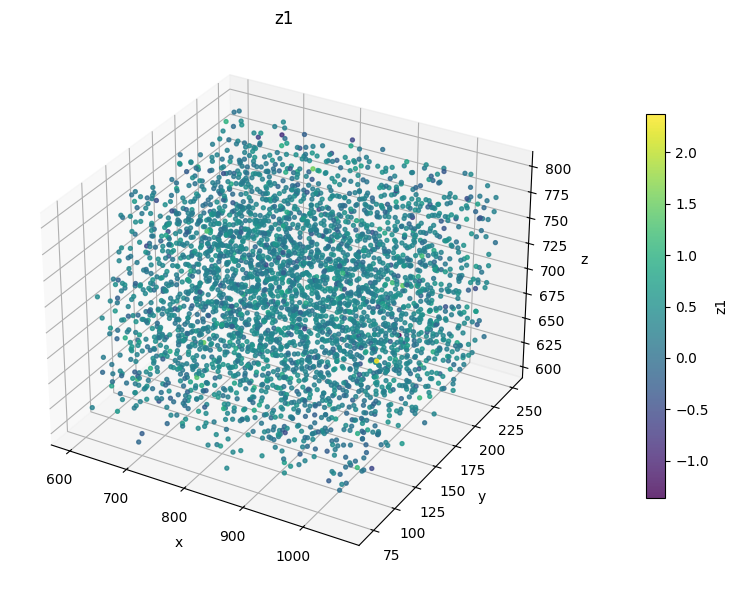

In [22]:
import matplotlib.pyplot as plt

df_plot = df_Z_full.dropna(
    subset=[
        "pt_position_x",
        "pt_position_y",
        "pt_position_z",
        *z_columns
    ]
).copy()

fig = plt.figure(figsize=(18, 6))

for i, z in enumerate(z_columns):

    ax = fig.add_subplot(1, len(z_columns), i + 1, projection="3d")

    sc = ax.scatter(
        df_plot["pt_position_x"],
        df_plot["pt_position_y"],
        df_plot["pt_position_z"],
        c=df_plot[z],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )

    ax.set_title(z)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

    cbar = fig.colorbar(
        sc,
        ax=ax,
        shrink=0.7,
        pad=0.05
    )
    cbar.set_label(z)

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\4023524896.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


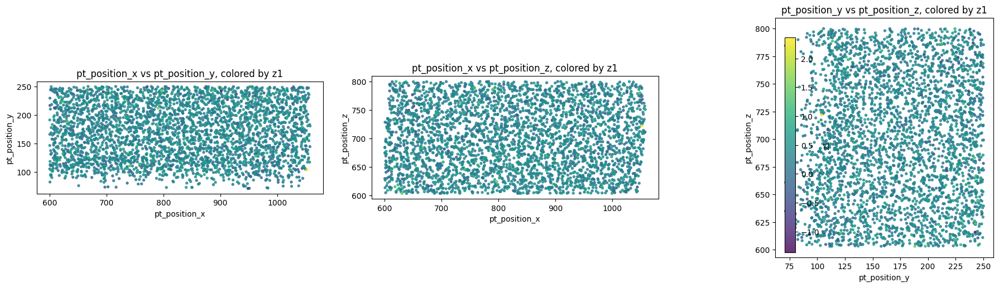

In [23]:
for z in z_columns:
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    pairs = [
        ("pt_position_x", "pt_position_y"),
        ("pt_position_x", "pt_position_z"),
        ("pt_position_y", "pt_position_z"),
    ]

    for ax, (a, b) in zip(axes, pairs):
        sc = ax.scatter(
            df_plot[a],
            df_plot[b],
            c=df_plot[z],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )
        ax.set_xlabel(a)
        ax.set_ylabel(b)
        ax.set_title(f"{a} vs {b}, colored by {z}")
        ax.set_aspect("equal", adjustable="box")

    plt.colorbar(sc, ax=axes, label=z)
    plt.tight_layout()
    plt.show()

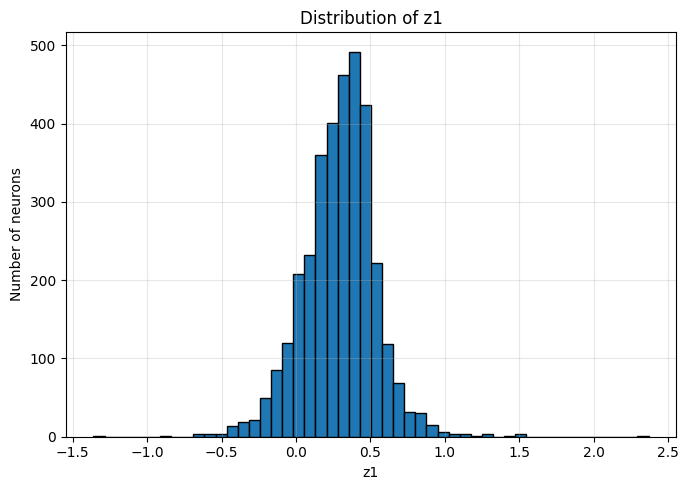


===== z1 =====
count    3408.000000
mean        0.292099
std         0.245434
min        -1.360400
25%         0.148741
50%         0.312764
75%         0.440912
max         2.368225
Name: z1, dtype: float64


In [24]:



for z in z_columns:

    plt.figure(figsize=(7,5))

    plt.hist(
        df_plot[z],
        bins=50,
        edgecolor="black"
    )

    plt.xlabel(z)
    plt.ylabel("Number of neurons")
    plt.title(f"Distribution of {z}")

    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"\n===== {z} =====")
    print(df_plot[z].describe())

In [25]:
for z in z_columns:
    for coord in ["pt_position_x", "pt_position_y", "pt_position_z"]:
        corr = df_plot[z].corr(df_plot[coord])
        print(f"corr({z}, {coord}) = {corr:.3f}")

corr(z1, pt_position_x) = 0.011
corr(z1, pt_position_y) = 0.037
corr(z1, pt_position_z) = -0.050


Z shape: (3408, 1)
Number of pairs: 11611056

===== z1 =====
    median_delta_z  mean_biological_distance  connection_probability  n_pairs  \
0         0.060419                188.016663                0.004885  3603270   
1         0.182225                189.306763                0.005373  2969636   
2         0.304487                190.651398                0.006054  2119506   
3         0.427206                191.785919                0.007178  1337620   
4         0.549887                193.771942                0.008492   758624   
5         0.673525                196.056580                0.009589   398280   
6         0.797769                197.934738                0.011122   204106   
7         0.921559                200.032166                0.011807   103160   
8         1.046205                200.779816                0.011253    52610   
9         1.169827                198.997726                0.009501    26312   
10        1.295556                201.611649    

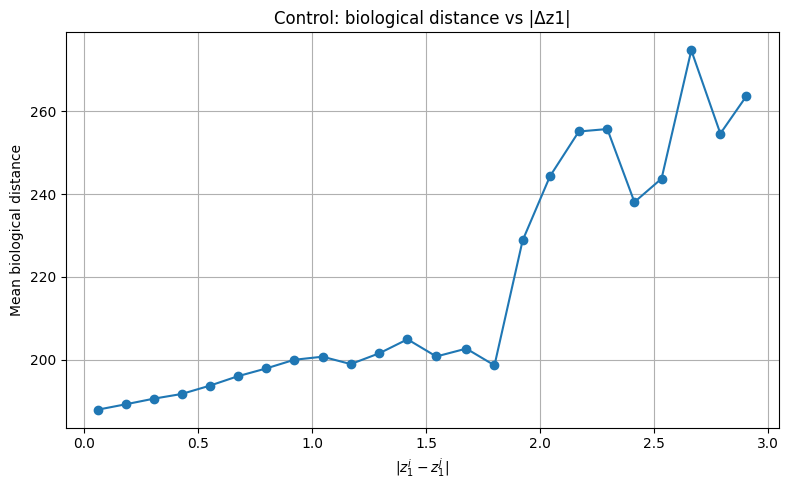

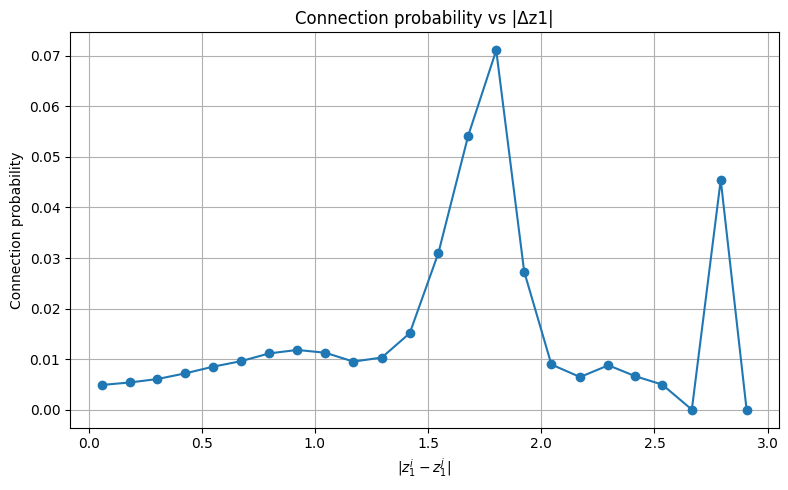

In [26]:
# ============================================================
# Latent dimension analysis
#
# For each latent dimension z_k:
# 1. Control graph:
#    Mean biological distance vs |z_k_pre - z_k_post|
#
# 2. Main graph:
#    Connection probability vs |z_k_pre - z_k_post|
#
# No normalization.
# Geometry is NOT included in |Δz_k|.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Config
# -------------------------

N_BINS = 30
MIN_PAIRS_PER_BIN = 10

# ============================================================
# 1. Convert tensors to numpy
# ============================================================

pre_idx_np = (
    pre_idx.detach().cpu().numpy()
    if hasattr(pre_idx, "detach")
    else np.asarray(pre_idx)
)

post_idx_np = (
    post_idx.detach().cpu().numpy()
    if hasattr(post_idx, "detach")
    else np.asarray(post_idx)
)

y_np = (
    y.detach().cpu().numpy()
    if hasattr(y, "detach")
    else np.asarray(y)
)

y_np = y_np.astype(np.float32)

# ============================================================
# 2. Recover biological positions
# ============================================================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

positions_df = (
    units_cleaned
    .drop_duplicates("pt_root_id")
    .set_index("pt_root_id")
)[
    [
        "pt_position_x",
        "pt_position_y",
        "pt_position_z",
    ]
]

pre_pos = positions_df.loc[pre_ids].to_numpy(dtype=np.float32)
post_pos = positions_df.loc[post_ids].to_numpy(dtype=np.float32)

biological_distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

# ============================================================
# 3. Recover latent vectors
# ============================================================

# Z should be:
# Z = model.Z.weight.detach().cpu().numpy()

Z_np = np.asarray(Z, dtype=np.float32)

Z_pre = Z_np[pre_idx_np]
Z_post = Z_np[post_idx_np]

print("Z shape:", Z_np.shape)
print("Number of pairs:", len(y_np))

# ============================================================
# 4. Loop over latent dimensions
# ============================================================

all_curves = {}

for k in range(DIM_TO_ANALYZE):

    delta_z = np.abs(
        Z_pre[:, k] - Z_post[:, k]
    )

    df = pd.DataFrame({
        "delta_z": delta_z,
        "biological_distance": biological_distance,
        "connected": y_np,
    })

    min_val = df["delta_z"].min()
    max_val = df["delta_z"].max()

    if min_val == max_val:
        print(f"z{k+1}: skipped because |Δz{k+1}| is constant.")
        continue

    bins = np.linspace(
        min_val,
        max_val,
        N_BINS + 1
    )

    df["delta_bin"] = pd.cut(
        df["delta_z"],
        bins=bins,
        include_lowest=True
    )

    curve = (
        df
        .groupby("delta_bin", observed=True)
        .agg(
            median_delta_z=("delta_z", "median"),
            mean_delta_z=("delta_z", "mean"),
            mean_biological_distance=("biological_distance", "mean"),
            connection_probability=("connected", "mean"),
            n_pairs=("connected", "size"),
            n_connections=("connected", "sum"),
        )
        .reset_index(drop=True)
    )

    curve = curve[
        curve["n_pairs"] >= MIN_PAIRS_PER_BIN
    ].copy()

    all_curves[f"z{k+1}"] = curve

    print(f"\n===== z{k+1} =====")
    print(
        curve[
            [
                "median_delta_z",
                "mean_biological_distance",
                "connection_probability",
                "n_pairs",
                "n_connections",
            ]
        ]
    )

    # ========================================================
    # Graph 1: biological distance vs |Δzk|
    # ========================================================

    plt.figure(figsize=(8, 5))

    plt.plot(
        curve["median_delta_z"],
        curve["mean_biological_distance"],
        marker="o"
    )

    plt.xlabel(rf"$|z_{{{k+1}}}^i - z_{{{k+1}}}^j|$")
    plt.ylabel("Mean biological distance")
    plt.title(f"Control: biological distance vs |Δz{k+1}|")

    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ========================================================
    # Graph 2: connection probability vs |Δzk|
    # ========================================================

    plt.figure(figsize=(8, 5))

    plt.plot(
        curve["median_delta_z"],
        curve["connection_probability"],
        marker="o"
    )

    plt.xlabel(rf"$|z_{{{k+1}}}^i - z_{{{k+1}}}^j|$")
    plt.ylabel("Connection probability")
    plt.title(f"Connection probability vs |Δz{k+1}|")

    plt.grid(True)
    plt.tight_layout()
    plt.show()

Z range: -1.3603998 2.3682249
z_pre range: -1.3603998 2.3682249
z_post range: -1.3603998 2.3682249
Number of all pairs: 11611056
Pairs with manually proofread presynaptic axon: 64733
Pairs without manually proofread presynaptic axon: 11546323
Number of manually proofread presynaptic neurons: 19
Number of non-proofread presynaptic neurons: 3389


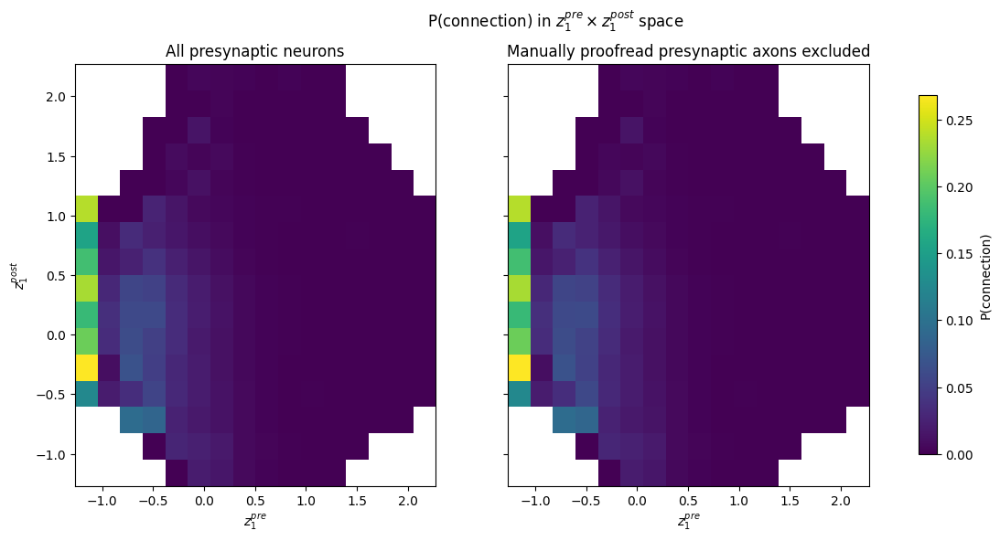

In [27]:
# ============================================================
# Heatmaps:
# 1. All presynaptic neurons
# 2. Excluding manually proofread presynaptic axons
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

K_DIM = 1
N_BINS = 20
MIN_PAIRS_PER_CELL = 20

k = K_DIM - 1

# Convert pair indices
pre_idx_np = (
    pre_idx.detach().cpu().numpy()
    if hasattr(pre_idx, "detach")
    else np.asarray(pre_idx)
)

post_idx_np = (
    post_idx.detach().cpu().numpy()
    if hasattr(post_idx, "detach")
    else np.asarray(post_idx)
)

# Current latent embedding
Z_np = np.asarray(Z, dtype=np.float32)

# Recompute from current Z
Z_pre = Z_np[pre_idx_np]
Z_post = Z_np[post_idx_np]

z_pre = Z_pre[:, k]
z_post = Z_post[:, k]

print("Z range:", Z_np[:, k].min(), Z_np[:, k].max())
print("z_pre range:", z_pre.min(), z_pre.max())
print("z_post range:", z_post.min(), z_post.max())


# ============================================================
# 2. Recover strategy_axon for each presynaptic neuron
# ============================================================

strategy_axon_by_id = (
    units_cleaned
    .drop_duplicates("pt_root_id")
    .set_index("pt_root_id")["strategy_axon"]
)

pre_strategy_axon = (
    pd.Series(pre_ids)
    .map(strategy_axon_by_id)
    .to_numpy()
)

# Assumption:
# strategy_axon == "none" or NaN -> not manually proofread
# any other value                  -> manually proofread

pre_axon_is_proofread = (
    pd.Series(pre_strategy_axon)
    .fillna("none")
    .astype(str)
    .str.strip()
    .str.lower()
    .ne("none")
    .to_numpy()
)

print(
    "Number of all pairs:",
    len(y_np)
)

print(
    "Pairs with manually proofread presynaptic axon:",
    pre_axon_is_proofread.sum()
)

print(
    "Pairs without manually proofread presynaptic axon:",
    (~pre_axon_is_proofread).sum()
)

print(
    "Number of manually proofread presynaptic neurons:",
    np.unique(pre_ids[pre_axon_is_proofread]).size
)

print(
    "Number of non-proofread presynaptic neurons:",
    np.unique(pre_ids[~pre_axon_is_proofread]).size
)


# ============================================================
# 3. Build pair DataFrame
# ============================================================

df_heat = pd.DataFrame({
    "z_pre": z_pre,
    "z_post": z_post,
    "connected": y_np,
    "biological_distance": biological_distance,
    "strategy_axon_pre": pre_strategy_axon,
    "axon_is_proofread_pre": pre_axon_is_proofread,
})


# ============================================================
# 4. Common bins for both heatmaps
# ============================================================

z_min = min(
    df_heat["z_pre"].min(),
    df_heat["z_post"].min()
)

z_max = max(
    df_heat["z_pre"].max(),
    df_heat["z_post"].max()
)

edges = np.linspace(
    z_min,
    z_max,
    N_BINS + 1
)


# ============================================================
# 5. Function to compute one heatmap
# ============================================================

def compute_heatmap(df_subset):

    df_subset = df_subset.copy()

    df_subset["z_pre_bin"] = pd.cut(
        df_subset["z_pre"],
        bins=edges,
        include_lowest=True
    )

    df_subset["z_post_bin"] = pd.cut(
        df_subset["z_post"],
        bins=edges,
        include_lowest=True
    )

    cell_stats = (
        df_subset
        .groupby(
            ["z_pre_bin", "z_post_bin"],
            observed=True
        )
        .agg(
            connection_prob=("connected", "mean"),
            n_pairs=("connected", "size"),
            n_connections=("connected", "sum"),
            mean_bio_distance=("biological_distance", "mean"),
        )
        .reset_index()
    )

    cell_stats.loc[
        cell_stats["n_pairs"] < MIN_PAIRS_PER_CELL,
        "connection_prob"
    ] = np.nan

    heat_prob = cell_stats.pivot(
        index="z_post_bin",
        columns="z_pre_bin",
        values="connection_prob"
    )

    return heat_prob


# ============================================================
# 6. Compute the two requested heatmaps
# ============================================================

# Heatmap 1:
# all neurons, regardless of proofreading status
heat_all = compute_heatmap(
    df_heat
)

# Heatmap 2:
# manually proofread presynaptic axons excluded
heat_without_proofread = compute_heatmap(
    df_heat[
        ~df_heat["axon_is_proofread_pre"]
    ]
)


# ============================================================
# 7. Common axes
# ============================================================

x_centers = np.array([
    interval.mid
    for interval in heat_all.columns
])

y_centers = np.array([
    interval.mid
    for interval in heat_all.index
])

extent = [
    x_centers.min(),
    x_centers.max(),
    y_centers.min(),
    y_centers.max()
]


# ============================================================
# 8. Common color scale
# ============================================================

combined_values = np.concatenate([
    heat_all.to_numpy().ravel(),
    heat_without_proofread.to_numpy().ravel()
])

vmin = 0
vmax = np.nanmax(combined_values)


# ============================================================
# 9. Plot the two heatmaps
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    sharex=True,
    sharey=True
)

# ------------------------------------------------------------
# All neurons
# ------------------------------------------------------------

im = axes[0].imshow(
    heat_all.values,
    origin="lower",
    aspect="auto",
    extent=extent,
    vmin=vmin,
    vmax=vmax
)

axes[0].set_title(
    "All presynaptic neurons"
)

axes[0].set_xlabel(
    rf"$z_{{{K_DIM}}}^{{pre}}$"
)

axes[0].set_ylabel(
    rf"$z_{{{K_DIM}}}^{{post}}$"
)


# ------------------------------------------------------------
# Proofread axons excluded
# ------------------------------------------------------------

axes[1].imshow(
    heat_without_proofread.values,
    origin="lower",
    aspect="auto",
    extent=extent,
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title(
    "Manually proofread presynaptic axons excluded"
)

axes[1].set_xlabel(
    rf"$z_{{{K_DIM}}}^{{pre}}$"
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

fig.colorbar(
    im,
    ax=axes,
    label="P(connection)",
    shrink=0.85
)

fig.suptitle(
    rf"P(connection) in "
    rf"$z_{{{K_DIM}}}^{{pre}} \times "
    rf"z_{{{K_DIM}}}^{{post}}$ space"
)

plt.show()

   neuron_idx          pt_root_id        z1  out_degree  in_degree  \
0           0  864691134884804602  0.143915        19.0       38.0   
1           1  864691134885076730  0.501523         4.0       39.0   
2           2  864691134885518074  0.329397         6.0       22.0   
3           3  864691134885576442  0.114838        31.0        7.0   
4           4  864691134885584634 -0.071351        62.0       11.0   

   around_minus_1_2  
0             False  
1             False  
2             False  
3             False  
4             False  

Neurons with z1 in [-1.30, -1.10]: 0

Global correlations
Spearman z1 vs out-degree: rho=-0.9062, p=0.000e+00
Spearman z1 vs in-degree:  rho=-0.1503, p=1.132e-18


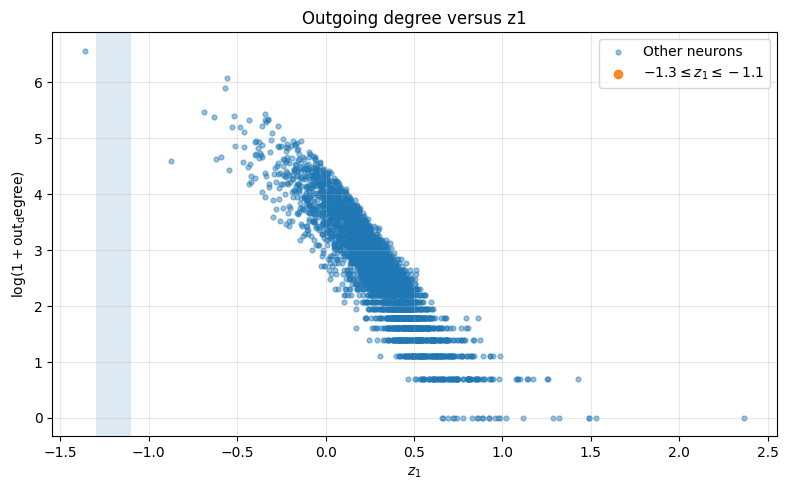

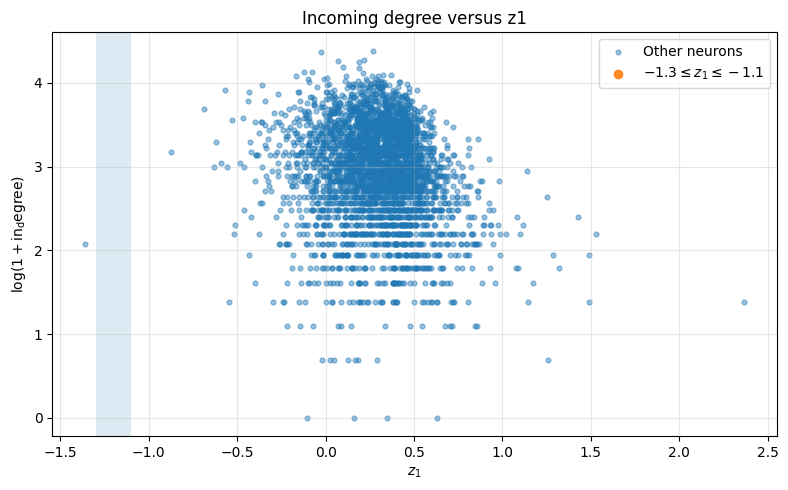


Group summary
            group  n_neurons  mean_out_degree  median_out_degree  \
0  z1 around -1.2          0              NaN                NaN   
1   other neurons       3408        20.953052               12.0   

   mean_in_degree  median_in_degree  
0             NaN               NaN  
1       20.953052              19.0  


In [28]:
# ============================================================
# Relation between z1 and outgoing / incoming degree
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu

# -------------------------
# Config
# -------------------------

Z1_CENTER = -1.2
Z1_HALF_WIDTH = 0.10

# Interval considered "around -1.2"
Z1_LOW = Z1_CENTER - Z1_HALF_WIDTH
Z1_HIGH = Z1_CENTER + Z1_HALF_WIDTH


# ============================================================
# 1. Convert pair arrays to numpy
# ============================================================

pre_idx_np = (
    pre_idx.detach().cpu().numpy()
    if hasattr(pre_idx, "detach")
    else np.asarray(pre_idx)
)

post_idx_np = (
    post_idx.detach().cpu().numpy()
    if hasattr(post_idx, "detach")
    else np.asarray(post_idx)
)

y_np = (
    y.detach().cpu().numpy()
    if hasattr(y, "detach")
    else np.asarray(y)
).astype(np.int32)


# ============================================================
# 2. Compute degree for every neuron
# ============================================================

n_neurons_local = Z.shape[0]

# Number of observed outgoing connections
out_degree = np.bincount(
    pre_idx_np,
    weights=y_np,
    minlength=n_neurons_local
)

# Number of observed incoming connections
in_degree = np.bincount(
    post_idx_np,
    weights=y_np,
    minlength=n_neurons_local
)

df_degree = pd.DataFrame({
    "neuron_idx": np.arange(n_neurons_local),
    "pt_root_id": np.asarray(all_ids),
    "z1": Z[:, 0],
    "out_degree": out_degree,
    "in_degree": in_degree,
})

df_degree["around_minus_1_2"] = df_degree["z1"].between(
    Z1_LOW,
    Z1_HIGH
)

print(df_degree.head())
print(
    f"\nNeurons with z1 in [{Z1_LOW:.2f}, {Z1_HIGH:.2f}]:",
    df_degree["around_minus_1_2"].sum()
)


# ============================================================
# 3. Global Spearman correlations
# ============================================================

rho_out, p_out = spearmanr(
    df_degree["z1"],
    df_degree["out_degree"]
)

rho_in, p_in = spearmanr(
    df_degree["z1"],
    df_degree["in_degree"]
)

print("\nGlobal correlations")

print(
    f"Spearman z1 vs out-degree: "
    f"rho={rho_out:.4f}, p={p_out:.3e}"
)

print(
    f"Spearman z1 vs in-degree:  "
    f"rho={rho_in:.4f}, p={p_in:.3e}"
)


# ============================================================
# 4. Scatter plots
# ============================================================

for degree_col, title in [
    ("out_degree", "Outgoing degree"),
    ("in_degree", "Incoming degree"),
]:

    plt.figure(figsize=(8, 5))

    normal = ~df_degree["around_minus_1_2"]
    selected = df_degree["around_minus_1_2"]

    plt.scatter(
        df_degree.loc[normal, "z1"],
        np.log1p(df_degree.loc[normal, degree_col]),
        s=12,
        alpha=0.45,
        label="Other neurons"
    )

    plt.scatter(
        df_degree.loc[selected, "z1"],
        np.log1p(df_degree.loc[selected, degree_col]),
        s=35,
        alpha=0.9,
        label=rf"${Z1_LOW:.1f} \leq z_1 \leq {Z1_HIGH:.1f}$"
    )

    plt.axvspan(
        Z1_LOW,
        Z1_HIGH,
        alpha=0.15
    )

    plt.xlabel(r"$z_1$")
    plt.ylabel(rf"$\log(1 + \mathrm{{{degree_col}}})$")
    plt.title(f"{title} versus z1")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. Compare neurons around -1.2 with all other neurons
# ============================================================

group_special = df_degree[df_degree["around_minus_1_2"]]
group_other = df_degree[~df_degree["around_minus_1_2"]]

summary = pd.DataFrame({
    "group": [
        "z1 around -1.2",
        "other neurons"
    ],
    "n_neurons": [
        len(group_special),
        len(group_other)
    ],
    "mean_out_degree": [
        group_special["out_degree"].mean(),
        group_other["out_degree"].mean()
    ],
    "median_out_degree": [
        group_special["out_degree"].median(),
        group_other["out_degree"].median()
    ],
    "mean_in_degree": [
        group_special["in_degree"].mean(),
        group_other["in_degree"].mean()
    ],
    "median_in_degree": [
        group_special["in_degree"].median(),
        group_other["in_degree"].median()
    ],
})

print("\nGroup summary")
print(summary)


# ============================================================
# 6. Non-parametric group comparisons
# ============================================================

if len(group_special) > 0 and len(group_other) > 0:

    test_out = mannwhitneyu(
        group_special["out_degree"],
        group_other["out_degree"],
        alternative="two-sided"
    )

    test_in = mannwhitneyu(
        group_special["in_degree"],
        group_other["in_degree"],
        alternative="two-sided"
    )

    print("\nMann–Whitney tests")

    print(
        f"Out-degree: statistic={test_out.statistic:.1f}, "
        f"p={test_out.pvalue:.3e}"
    )

    print(
        f"In-degree: statistic={test_in.statistic:.1f}, "
        f"p={test_in.pvalue:.3e}"
    )

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\776809946.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = df.groupby("distance_bin").agg(


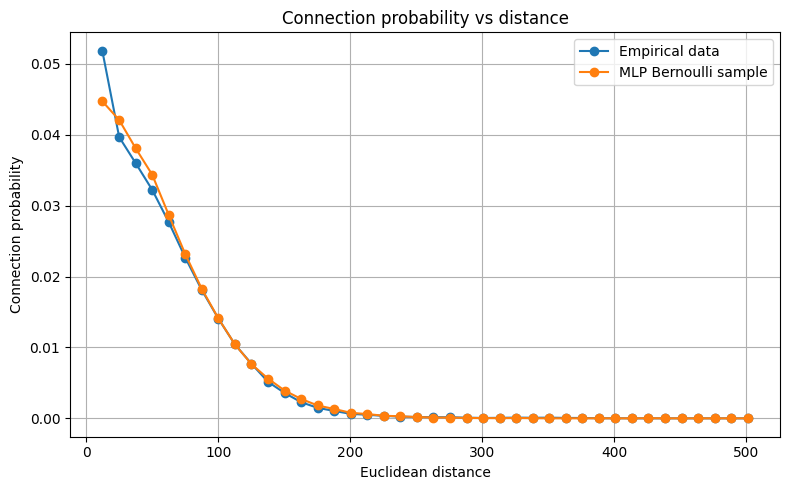

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Euclidean distances
# =========================

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

# =========================
# 3. MLP probabilities
# =========================

model.eval()

with torch.no_grad():
    p_mlp = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

# =========================
# 4. Bernoulli realization
# =========================

rng = np.random.default_rng(42)

y_mlp = rng.binomial(
    n=1,
    p=p_mlp
)

y_emp = y.cpu().numpy()

# =========================
# 5. Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "empirical": y_emp,
    "mlp": y_mlp
})

df["distance_bin"] = pd.cut(
    df["distance"],
    bins=40
)

# =========================
# 6. Compute connection probability per bin
# =========================

curve = df.groupby("distance_bin").agg(
    empirical_prob=("empirical", "mean"),
    mlp_prob=("mlp", "mean"),
    n_pairs=("empirical", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# =========================
# 7. Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical data"
)

plt.plot(
    centers,
    curve["mlp_prob"],
    marker="o",
    label="MLP Bernoulli sample"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Loaded Geometry MLP
Best epoch: 40
Best val loss: 0.03170956085877077
p_geo: (11611056,)
p_hybrid: (11611056,)
Hybrid
3.7157395e-12 0.6871771 0.006392692
Geometry
8.883911e-08 0.08455417 0.006028184
       pre_pt_root_id     post_pt_root_id    distance    y     p_geo  \
0  864691134884804602  864691136267238900  125.477081  1.0  0.007628   
1  864691134885076730  864691135719709489   54.820595  1.0  0.040912   
2  864691134885076730  864691135841733859   57.971935  1.0  0.023675   
3  864691134885518074  864691136700131694   46.501579  1.0  0.030841   
4  864691134885576442  864691136811834227  143.907272  1.0  0.016882   

   p_hybrid   delta_p  
0  0.009873  0.257926  
1  0.009993 -1.409552  
2  0.007013 -1.216666  
3  0.014352 -0.764990  
4  0.011808 -0.357453  
              p_geo      p_hybrid       delta_p
count  1.161106e+07  1.161106e+07  1.161106e+07
mean   6.028184e-03  6.392692e-03 -7.540282e-01
std    9.867680e-03  1.798532e-02  1.213950e+00
min    8.883911e-08  3.715740e-1

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\2189810690.py:233: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


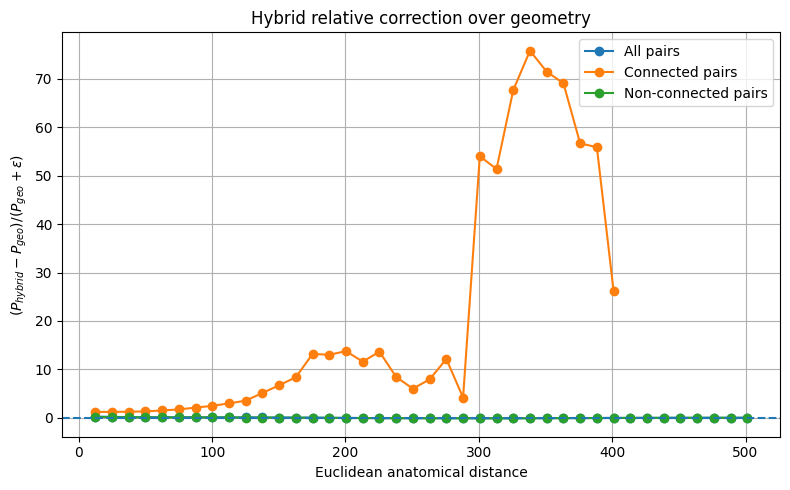

In [30]:
# ============================================================
# Compare Hybrid model vs 3D Geometry MLP baseline
# What does the latent part add beyond geometry?
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# -------------------------
# Config
# -------------------------

GEO_CHECKPOINT_DIR = (
    "checkpoints_3dgeo_MLP_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_lr3"
)

GEO_DIM = 3
BATCH_SIZE_PRED = 32768

geo_ckpt_path = os.path.join(
    GEO_CHECKPOINT_DIR,
    f"best_dim_{GEO_DIM}.pt"
)

# ============================================================
# 1. Convert indices / labels to numpy
# ============================================================

pre_idx_np = (
    pre_idx.detach().cpu().numpy()
    if torch.is_tensor(pre_idx)
    else np.asarray(pre_idx)
)

post_idx_np = (
    post_idx.detach().cpu().numpy()
    if torch.is_tensor(post_idx)
    else np.asarray(post_idx)
)

y_np = (
    y.detach().cpu().numpy()
    if torch.is_tensor(y)
    else np.asarray(y)
)

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

# ============================================================
# 2. Build geometry input X_geo on the SAME pairs
# ============================================================

id_to_pos = units_cleaned.set_index("pt_root_id")[
    [
        "pt_position_x",
        "pt_position_y",
        "pt_position_z",
    ]
]

pre_xyz = id_to_pos.loc[pre_ids].to_numpy(dtype=np.float32)
post_xyz = id_to_pos.loc[post_ids].to_numpy(dtype=np.float32)

X_geo_np = np.concatenate(
    [
        pre_xyz,
        post_xyz,
    ],
    axis=1
).astype(np.float32)

distance = np.linalg.norm(
    pre_xyz - post_xyz,
    axis=1
)

# ============================================================
# 3. Define / load geometry model
# Important: same architecture as your 3D geo baseline
# ============================================================

class GeometryMLP(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()

        self.mlp = nn.Sequential(
            nn.Linear(6, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, X):
        return self.mlp(X).squeeze(1)

    def forward(self, X):
        return torch.sigmoid(
            self.forward_logits(X)
        )


geo_model = GeometryMLP(
    hidden=64
).to(DEVICE)

geo_ckpt = torch.load(
    geo_ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

geo_model.load_state_dict(
    geo_ckpt["model_state_dict"]
)

geo_model.eval()

print("Loaded Geometry MLP")
print("Best epoch:", geo_ckpt["best_epoch"])
print("Best val loss:", geo_ckpt["best_val_loss"])

# ============================================================
# 4. Predict p_geo by batches
# ============================================================

p_geo_batches = []

with torch.no_grad():

    for start in range(0, len(X_geo_np), BATCH_SIZE_PRED):

        end = start + BATCH_SIZE_PRED

        Xb = torch.tensor(
            X_geo_np[start:end],
            dtype=torch.float32,
            device=DEVICE
        )

        pb = geo_model(Xb)

        p_geo_batches.append(
            pb.detach().cpu().numpy()
        )

p_geo = np.concatenate(p_geo_batches)

print("p_geo:", p_geo.shape)

# ============================================================
# 5. Predict p_hybrid by batches
# The hybrid model must already be loaded as `model`
# ============================================================

p_hybrid_batches = []

model.eval()

with torch.no_grad():

    for start in range(0, len(y_np), BATCH_SIZE_PRED):

        end = start + BATCH_SIZE_PRED

        pre_b = torch.tensor(
            pre_idx_np[start:end],
            dtype=torch.long,
            device=DEVICE
        )

        post_b = torch.tensor(
            post_idx_np[start:end],
            dtype=torch.long,
            device=DEVICE
        )

        pb = model(pre_b, post_b)

        p_hybrid_batches.append(
            pb.detach().cpu().numpy()
        )

p_hybrid = np.concatenate(p_hybrid_batches)

print("p_hybrid:", p_hybrid.shape)

# ============================================================
# 6. Delta probability
# ============================================================
print("Hybrid")
print(p_hybrid.min(), p_hybrid.max(), p_hybrid.mean())

print("Geometry")
print(p_geo.min(), p_geo.max(), p_geo.mean())
#delta_p = (p_hybrid - p_geo) / (p_geo + 1e-5)
delta_p = np.log(p_hybrid/(p_geo + 1e-8))

df_delta = pd.DataFrame({
    "pre_pt_root_id": pre_ids,
    "post_pt_root_id": post_ids,
    "distance": distance,
    "y": y_np,
    "p_geo": p_geo,
    "p_hybrid": p_hybrid,
    "delta_p": delta_p,
})

print(df_delta.head())
print(df_delta[["p_geo", "p_hybrid", "delta_p"]].describe())

# ============================================================
# 7. Relative hybrid correction vs geometry
# ============================================================

EPS = 1e-5

df_delta["delta_relative"] = (
    df_delta["p_hybrid"] - df_delta["p_geo"]
) / (df_delta["p_geo"] + EPS)

df_delta["distance_bin"] = pd.cut(
    df_delta["distance"],
    bins=40
)

curve = (
    df_delta
    .groupby("distance_bin")
    .agg(
        all_pairs=("delta_relative", "mean"),
        connected=("delta_relative",
                   lambda x: x[df_delta.loc[x.index, "y"] == 1].mean()),
        non_connected=("delta_relative",
                       lambda x: x[df_delta.loc[x.index, "y"] == 0].mean()),
    )
)

centers = np.array([
    b.mid for b in curve.index
])

plt.figure(figsize=(8,5))

plt.plot(
    centers,
    curve["all_pairs"],
    marker="o",
    label="All pairs"
)

plt.plot(
    centers,
    curve["connected"],
    marker="o",
    label="Connected pairs"
)

plt.plot(
    centers,
    curve["non_connected"],
    marker="o",
    label="Non-connected pairs"
)

plt.axhline(0, ls="--")

plt.xlabel("Euclidean anatomical distance")
plt.ylabel(r"$(P_{hybrid}-P_{geo})/(P_{geo}+\varepsilon)$")
plt.title("Hybrid relative correction over geometry")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# Within-presynaptic-neuron AUC
# ============================================================

from sklearn.metrics import roc_auc_score

# Keep only the test pairs
test_indices = np.asarray(test_set.indices)
df_test = df_delta.iloc[test_indices].copy()

results_within_pre = []

# One AUC for each presynaptic neuron
for pre_id, group in df_test.groupby("pre_pt_root_id"):

    # AUC requires at least one connection and one non-connection
    if group["y"].nunique() < 2:
        continue

    results_within_pre.append({
        "pre_pt_root_id": pre_id,
        "n_test_pairs": len(group),
        "n_connections": int(group["y"].sum()),
        "auc_geo": roc_auc_score(
            group["y"],
            group["p_geo"]
        ),
        "auc_hybrid": roc_auc_score(
            group["y"],
            group["p_hybrid"]
        )
    })


auc_within_pre = pd.DataFrame(results_within_pre)

auc_within_pre["delta_auc"] = (
    auc_within_pre["auc_hybrid"]
    - auc_within_pre["auc_geo"]
)


# ============================================================
# Global AUC on the same test set
# ============================================================

global_auc_geo = roc_auc_score(
    df_test["y"],
    df_test["p_geo"]
)

global_auc_hybrid = roc_auc_score(
    df_test["y"],
    df_test["p_hybrid"]
)


# ============================================================
# Results
# ============================================================

print("Number of presynaptic neurons with a valid AUC:",
      len(auc_within_pre))

print("\nGlobal AUC")
print(f"Geometry: {global_auc_geo:.4f}")
print(f"Hybrid:   {global_auc_hybrid:.4f}")
print(f"Gain:     {global_auc_hybrid - global_auc_geo:+.4f}")

print("\nMean within-pre AUC")
print(f"Geometry: {auc_within_pre['auc_geo'].mean():.4f}")
print(f"Hybrid:   {auc_within_pre['auc_hybrid'].mean():.4f}")
print(f"Gain:     {auc_within_pre['delta_auc'].mean():+.4f}")

print("\nMedian within-pre AUC")
print(f"Geometry: {auc_within_pre['auc_geo'].median():.4f}")
print(f"Hybrid:   {auc_within_pre['auc_hybrid'].median():.4f}")
print(f"Gain:     {auc_within_pre['delta_auc'].median():+.4f}")

Number of presynaptic neurons with a valid AUC: 2241

Global AUC
Geometry: 0.8604
Hybrid:   0.9092
Gain:     +0.0488

Mean within-pre AUC
Geometry: 0.8631
Hybrid:   0.8694
Gain:     +0.0063

Median within-pre AUC
Geometry: 0.8911
Hybrid:   0.8962
Gain:     +0.0056


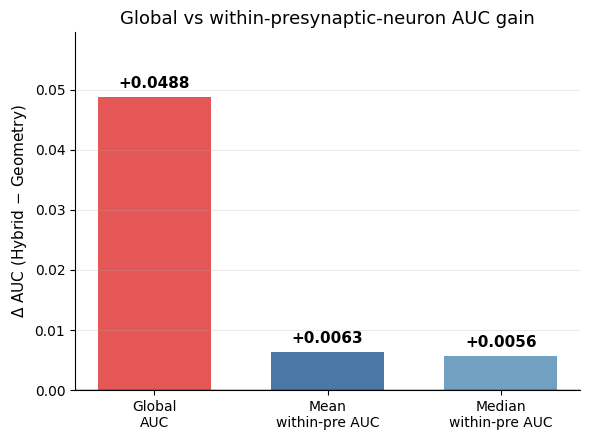

In [49]:
# ============================================================
# Plot: Global gain vs within-presynaptic-neuron gain
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


global_gain = (
    global_auc_hybrid
    - global_auc_geo
)

mean_within_gain = (
    auc_within_pre["delta_auc"].mean()
)

median_within_gain = (
    auc_within_pre["delta_auc"].median()
)


labels = [
    "Global\nAUC",
    "Mean\nwithin-pre AUC",
    "Median\nwithin-pre AUC",
]

gains = [
    global_gain,
    mean_within_gain,
    median_within_gain,
]


fig, ax = plt.subplots(
    figsize=(6, 4.5)
)

bars = ax.bar(
    labels,
    gains,
    color=[
        "#E45756",
        "#4C78A8",
        "#72A0C1",
    ],
    width=0.65,
)


# Display values above the bars
for bar, value in zip(bars, gains):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.001,
        f"{value:+.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )


ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_ylabel(
    r"$\Delta$ AUC (Hybrid − Geometry)",
    fontsize=11,
)

ax.set_title(
    "Global vs within-presynaptic-neuron AUC gain",
    fontsize=13,
)

ax.set_ylim(
    min(0, min(gains) - 0.005),
    max(gains) * 1.22,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

plt.savefig(
    "global_vs_within_pre_auc_gain.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\2259435429.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin_id, sub in df_auc.groupby("distance_bin"):


                   distance_bin  bin_center  n_pairs  n_connections  \
0   (5.997999999999999, 31.083]     18.5405    84142           3549   
1              (31.083, 56.166]     43.6245   354088          11921   
2               (56.166, 81.25]     68.7080   707434          17573   
3              (81.25, 106.333]     93.7915  1042966          16607   
4            (106.333, 131.417]    118.8750  1286506          11591   
5              (131.417, 156.5]    143.9585  1375720           6007   
6              (156.5, 181.584]    169.0420  1290100           2440   
7            (181.584, 206.667]    194.1255  1102940            935   
8            (206.667, 231.751]    219.2090   906302            388   
9            (231.751, 256.834]    244.2925   757518            165   
10           (256.834, 281.918]    269.3760   641232            102   
11           (281.918, 307.001]    294.4595   542338             40   
12           (307.001, 332.085]    319.5430   451900             39   
13    

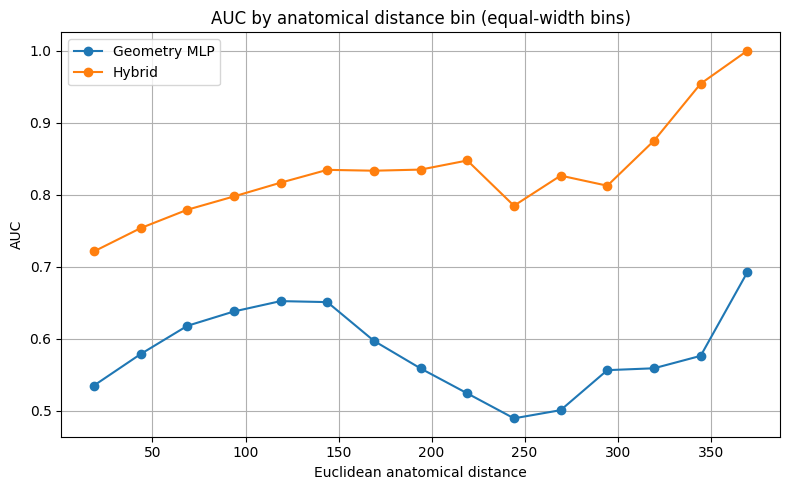

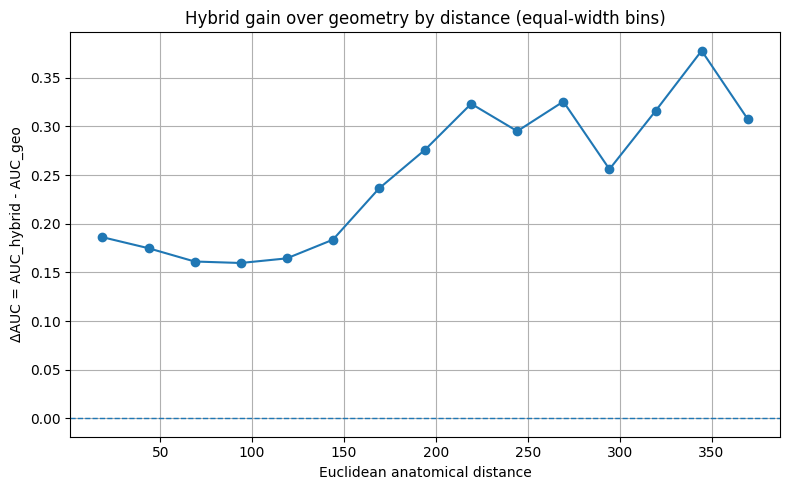

In [32]:
from sklearn.metrics import roc_auc_score

# ============================================================
# AUC by anatomical distance bin
# ============================================================

N_BINS = 20

df_auc = df_delta.copy()

# Create equal-width bins based on distance
min_dist = df_auc["distance"].min()
max_dist = df_auc["distance"].max()
bin_edges = np.linspace(min_dist, max_dist, N_BINS + 1)

df_auc["distance_bin"] = pd.cut(
    df_auc["distance"],
    bins=bin_edges,
    include_lowest=True
)

rows = []

for bin_id, sub in df_auc.groupby("distance_bin"):

    n_pos = int(sub["y"].sum())
    n_neg = int(len(sub) - n_pos)

    # AUC impossible si une seule classe dans le bin
    if n_pos < 5 or n_neg < 5:
        continue

    auc_geo = roc_auc_score(
        sub["y"],
        sub["p_geo"]
    )

    auc_hybrid = roc_auc_score(
        sub["y"],
        sub["p_hybrid"]
    )

    rows.append({
        "distance_bin": bin_id,
        "bin_center": bin_id.mid,
        "n_pairs": len(sub),
        "n_connections": n_pos,
        "connection_rate": n_pos / len(sub),
        "auc_geo": auc_geo,
        "auc_hybrid": auc_hybrid,
        "delta_auc": auc_hybrid - auc_geo,
    })

auc_by_distance = pd.DataFrame(rows)

print(auc_by_distance)

# Plot: AUC comparison
plt.figure(figsize=(8, 5))

plt.plot(
    auc_by_distance["bin_center"],
    auc_by_distance["auc_geo"],
    marker="o",
    label="Geometry MLP"
)

plt.plot(
    auc_by_distance["bin_center"],
    auc_by_distance["auc_hybrid"],
    marker="o",
    label="Hybrid"
)

plt.xlabel("Euclidean anatomical distance")
plt.ylabel("AUC")
plt.title("AUC by anatomical distance bin (equal-width bins)")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Plot: Delta AUC
plt.figure(figsize=(8, 5))

plt.axhline(0, linestyle="--", linewidth=1)

plt.plot(
    auc_by_distance["bin_center"],
    auc_by_distance["delta_auc"],
    marker="o"
)

plt.xlabel("Euclidean anatomical distance")
plt.ylabel("ΔAUC = AUC_hybrid - AUC_geo")
plt.title("Hybrid gain over geometry by distance (equal-width bins)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
print(auc_by_distance[[
    "bin_center",
    "n_pairs",
    "n_connections",
    "connection_rate",
    "auc_geo",
    "auc_hybrid",
    "delta_auc",
]])

    bin_center  n_pairs  n_connections  connection_rate   auc_geo  auc_hybrid  \
0      18.5405    84142           3549         0.042179  0.535143    0.721275   
1      43.6245   354088          11921         0.033667  0.578789    0.753578   
2      68.7080   707434          17573         0.024840  0.617970    0.779110   
3      93.7915  1042966          16607         0.015923  0.637960    0.797572   
4     118.8750  1286506          11591         0.009010  0.652296    0.816665   
5     143.9585  1375720           6007         0.004366  0.650923    0.834465   
6     169.0420  1290100           2440         0.001891  0.597107    0.833266   
7     194.1255  1102940            935         0.000848  0.558817    0.834821   
8     219.2090   906302            388         0.000428  0.524235    0.847447   
9     244.2925   757518            165         0.000218  0.489606    0.784658   
10    269.3760   641232            102         0.000159  0.500971    0.826451   
11    294.4595   542338     

Top positive threshold: 1.9843912959098775
Top negative threshold: -3.980042374134064

Top +delta_p
n: 116111
connection rate: 0.048083298
mean distance: 194.0251
mean p_geo: 0.0040162047
mean p_hybrid: 0.047061637
mean delta_p: 2.5249841

Top -delta_p
n: 116111
connection rate: 0.00014641162
mean distance: 230.65233
mean p_geo: 0.003953947
mean p_hybrid: 3.1831973e-05
mean delta_p: -5.28553


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3531368059.py:67: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin_id, bin_df in df_delta.groupby("distance_bin"):


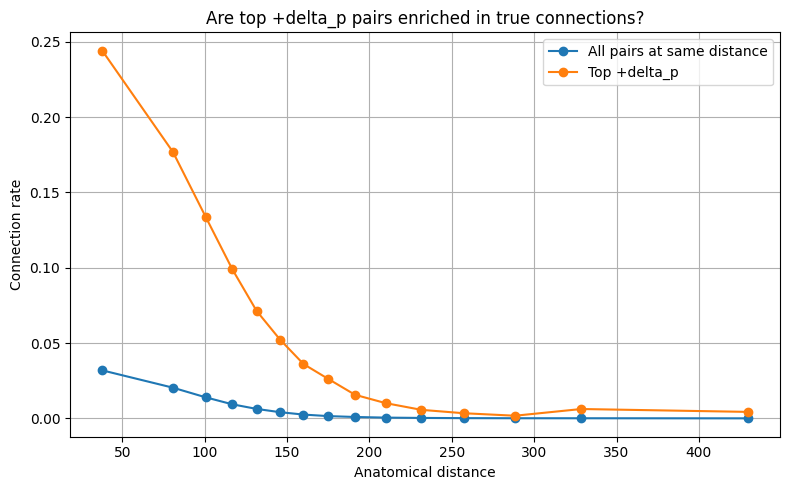


z1
Top +delta_p
mean pre: -0.4448297
mean post: 0.25812373
mean |delta|: 0.70625806
Top -delta_p
mean pre: 1.0959727
mean post: 0.3201325
mean |delta|: 0.7951381


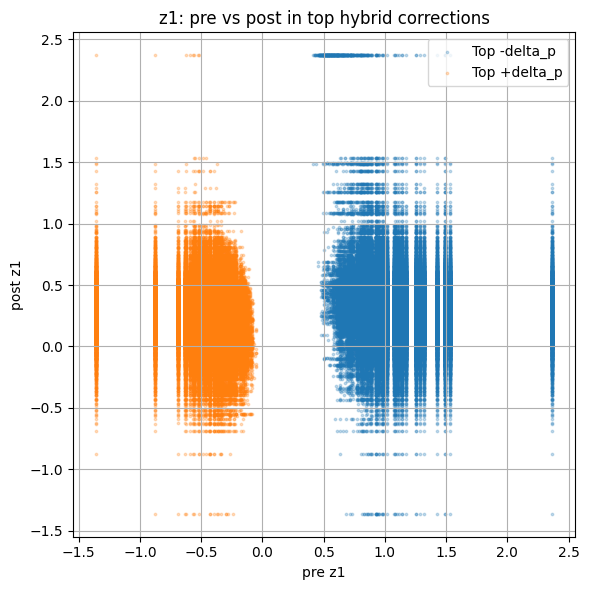

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3531368059.py:245: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("z_bin")


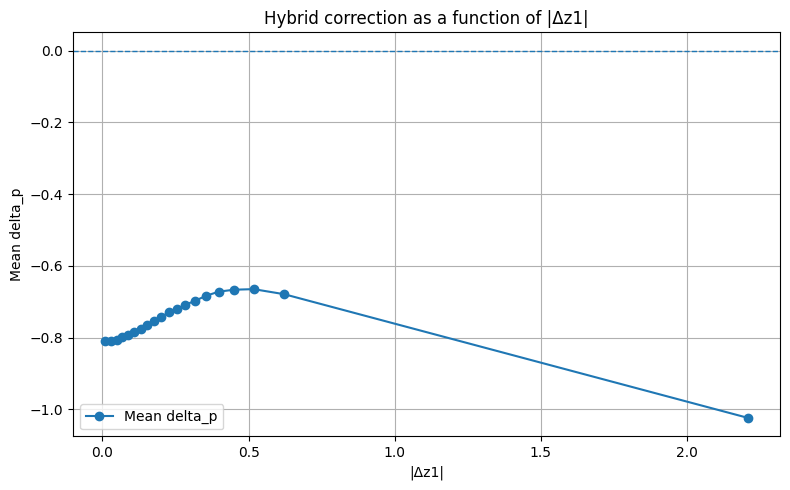

In [34]:
# ============================================================
# Deeper analysis of hybrid correction over geometry
# Requires:
#   df_delta with columns:
#   pre_pt_root_id, post_pt_root_id, distance, y, p_geo, p_hybrid, delta_p
#
#   df_Z_full with columns:
#   pt_root_id, z1, z2, ...
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TOP_FRAC = 0.01
N_DISTANCE_BINS = 15

# ============================================================
# 1. Define top positive / negative hybrid corrections
# ============================================================

q_pos = df_delta["delta_p"].quantile(1 - TOP_FRAC)
q_neg = df_delta["delta_p"].quantile(TOP_FRAC)

top_pos = df_delta[df_delta["delta_p"] >= q_pos].copy()
top_neg = df_delta[df_delta["delta_p"] <= q_neg].copy()

print("Top positive threshold:", q_pos)
print("Top negative threshold:", q_neg)

print("\nTop +delta_p")
print("n:", len(top_pos))
print("connection rate:", top_pos["y"].mean())
print("mean distance:", top_pos["distance"].mean())
print("mean p_geo:", top_pos["p_geo"].mean())
print("mean p_hybrid:", top_pos["p_hybrid"].mean())
print("mean delta_p:", top_pos["delta_p"].mean())

print("\nTop -delta_p")
print("n:", len(top_neg))
print("connection rate:", top_neg["y"].mean())
print("mean distance:", top_neg["distance"].mean())
print("mean p_geo:", top_neg["p_geo"].mean())
print("mean p_hybrid:", top_neg["p_hybrid"].mean())
print("mean delta_p:", top_neg["delta_p"].mean())


# ============================================================
# 2. Compare top +delta_p to distance-matched controls
# ============================================================

df_delta["distance_bin"] = pd.qcut(
    df_delta["distance"],
    q=N_DISTANCE_BINS,
    duplicates="drop"
)

top_pos["distance_bin"] = pd.cut(
    top_pos["distance"],
    bins=[b.left for b in df_delta["distance_bin"].cat.categories] 
         + [df_delta["distance_bin"].cat.categories[-1].right],
    include_lowest=True
)

matched_rows = []

for bin_id, bin_df in df_delta.groupby("distance_bin"):
    top_bin = top_pos[
        (top_pos["distance"] >= bin_id.left)
        & (top_pos["distance"] <= bin_id.right)
    ]

    if len(top_bin) == 0:
        continue

    matched_rows.append({
        "bin_center": bin_id.mid,
        "n_all": len(bin_df),
        "n_top_pos": len(top_bin),

        "conn_rate_all": bin_df["y"].mean(),
        "conn_rate_top_pos": top_bin["y"].mean(),

        "mean_delta_all": bin_df["delta_p"].mean(),
        "mean_delta_top_pos": top_bin["delta_p"].mean(),

        "mean_p_geo_all": bin_df["p_geo"].mean(),
        "mean_p_geo_top_pos": top_bin["p_geo"].mean(),

        "mean_p_hybrid_all": bin_df["p_hybrid"].mean(),
        "mean_p_hybrid_top_pos": top_bin["p_hybrid"].mean(),
    })

matched_summary = pd.DataFrame(matched_rows)

plt.figure(figsize=(8, 5))

plt.plot(
    matched_summary["bin_center"],
    matched_summary["conn_rate_all"],
    marker="o",
    label="All pairs at same distance"
)

plt.plot(
    matched_summary["bin_center"],
    matched_summary["conn_rate_top_pos"],
    marker="o",
    label="Top +delta_p"
)

plt.xlabel("Anatomical distance")
plt.ylabel("Connection rate")
plt.title("Are top +delta_p pairs enriched in true connections?")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 3. Add latent variables z_pre / z_post to df_delta
# ============================================================

z_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

z_df = df_Z_full[
    ["pt_root_id"] + z_cols
].drop_duplicates("pt_root_id")

pre_z_df = z_df.rename(
    columns={
        "pt_root_id": "pre_pt_root_id",
        **{c: f"pre_{c}" for c in z_cols}
    }
)

post_z_df = z_df.rename(
    columns={
        "pt_root_id": "post_pt_root_id",
        **{c: f"post_{c}" for c in z_cols}
    }
)

df_latent_delta = df_delta.merge(
    pre_z_df,
    on="pre_pt_root_id",
    how="left"
).merge(
    post_z_df,
    on="post_pt_root_id",
    how="left"
)

for c in z_cols:
    df_latent_delta[f"abs_delta_{c}"] = np.abs(
        df_latent_delta[f"pre_{c}"]
        - df_latent_delta[f"post_{c}"]
    )

# redefine top groups after merge
top_pos_latent = df_latent_delta[
    df_latent_delta["delta_p"] >= q_pos
].copy()

top_neg_latent = df_latent_delta[
    df_latent_delta["delta_p"] <= q_neg
].copy()


# ============================================================
# 4. Compare latent distributions in top positive / negative
# ============================================================

for c in z_cols:
    print("\n==============================")
    print(c)
    print("==============================")

    print("Top +delta_p")
    print("mean pre:", top_pos_latent[f"pre_{c}"].mean())
    print("mean post:", top_pos_latent[f"post_{c}"].mean())
    print("mean |delta|:", top_pos_latent[f"abs_delta_{c}"].mean())

    print("Top -delta_p")
    print("mean pre:", top_neg_latent[f"pre_{c}"].mean())
    print("mean post:", top_neg_latent[f"post_{c}"].mean())
    print("mean |delta|:", top_neg_latent[f"abs_delta_{c}"].mean())


# ============================================================
# 5. Scatter z_pre vs z_post for top corrections
# ============================================================

for c in z_cols:

    plt.figure(figsize=(6, 6))

    plt.scatter(
        top_neg_latent[f"pre_{c}"],
        top_neg_latent[f"post_{c}"],
        s=3,
        alpha=0.25,
        label="Top -delta_p"
    )

    plt.scatter(
        top_pos_latent[f"pre_{c}"],
        top_pos_latent[f"post_{c}"],
        s=3,
        alpha=0.25,
        label="Top +delta_p"
    )

    plt.xlabel(f"pre {c}")
    plt.ylabel(f"post {c}")
    plt.title(f"{c}: pre vs post in top hybrid corrections")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# 6. Delta_p as a function of |delta_z|
# ============================================================

for c in z_cols:

    tmp = df_latent_delta[
        ["delta_p", f"abs_delta_{c}", "y"]
    ].dropna().copy()

    tmp["z_bin"] = pd.qcut(
        tmp[f"abs_delta_{c}"],
        q=20,
        duplicates="drop"
    )

    curve_z = (
        tmp
        .groupby("z_bin")
        .agg(
            mean_delta_p=("delta_p", "mean"),
            connection_rate=("y", "mean"),
            n_pairs=("y", "size")
        )
    )

    curve_z["bin_center"] = np.array([
        b.mid for b in curve_z.index
    ])

    plt.figure(figsize=(8, 5))

    plt.plot(
        curve_z["bin_center"],
        curve_z["mean_delta_p"],
        marker="o",
        label="Mean delta_p"
    )

    plt.axhline(0, linestyle="--", linewidth=1)

    plt.xlabel(f"|Δ{c}|")
    plt.ylabel("Mean delta_p")
    plt.title(f"Hybrid correction as a function of |Δ{c}|")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\776809946.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = df.groupby("distance_bin").agg(


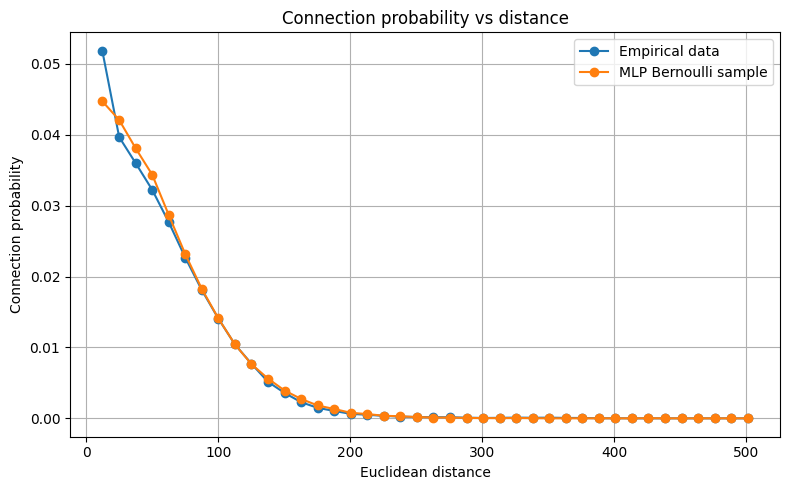

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Euclidean distances
# =========================

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

# =========================
# 3. MLP probabilities
# =========================

model.eval()

with torch.no_grad():
    p_mlp = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

# =========================
# 4. Bernoulli realization
# =========================

rng = np.random.default_rng(42)

y_mlp = rng.binomial(
    n=1,
    p=p_mlp
)

y_emp = y.cpu().numpy()

# =========================
# 5. Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "empirical": y_emp,
    "mlp": y_mlp
})

df["distance_bin"] = pd.cut(
    df["distance"],
    bins=40
)

# =========================
# 6. Compute connection probability per bin
# =========================

curve = df.groupby("distance_bin").agg(
    empirical_prob=("empirical", "mean"),
    mlp_prob=("mlp", "mean"),
    n_pairs=("empirical", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# =========================
# 7. Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical data"
)

plt.plot(
    centers,
    curve["mlp_prob"],
    marker="o",
    label="MLP Bernoulli sample"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3132833221.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 29
Best val loss: 0.0284


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3132833221.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3132833221.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.031

Analyzing dim = 2
Loaded best epoch: 29
Best val loss: 0.0281


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3132833221.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3132833221.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.029

Analyzing dim = 3
Loaded best epoch: 29
Best val loss: 0.0278


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3132833221.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_10284\3132833221.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.035


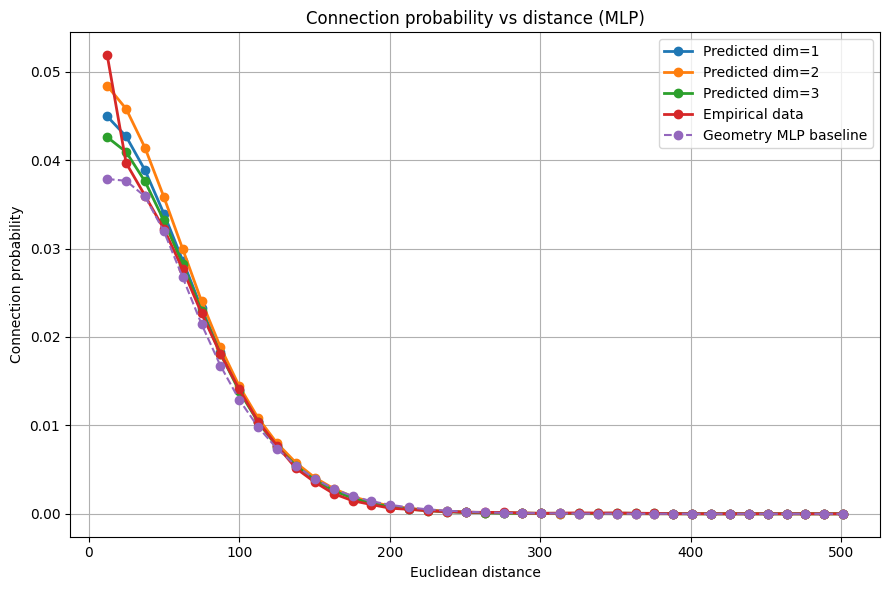

dim=3 corr=0.035


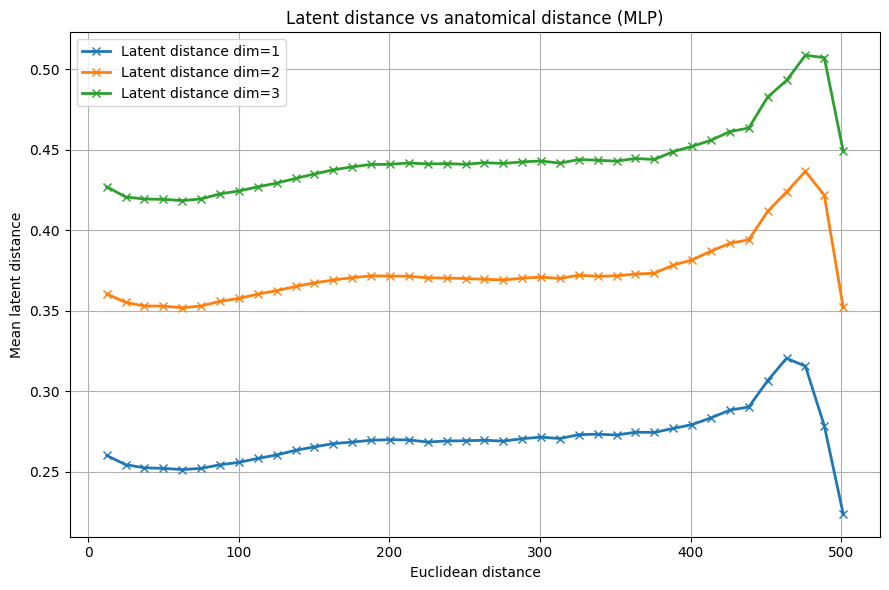

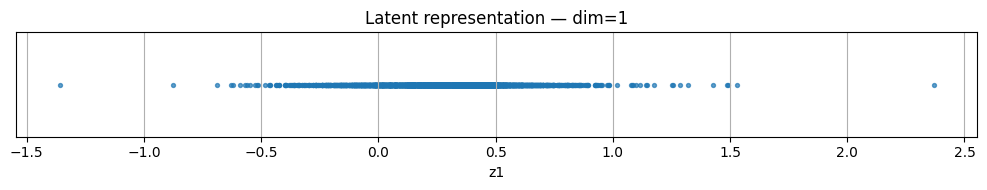

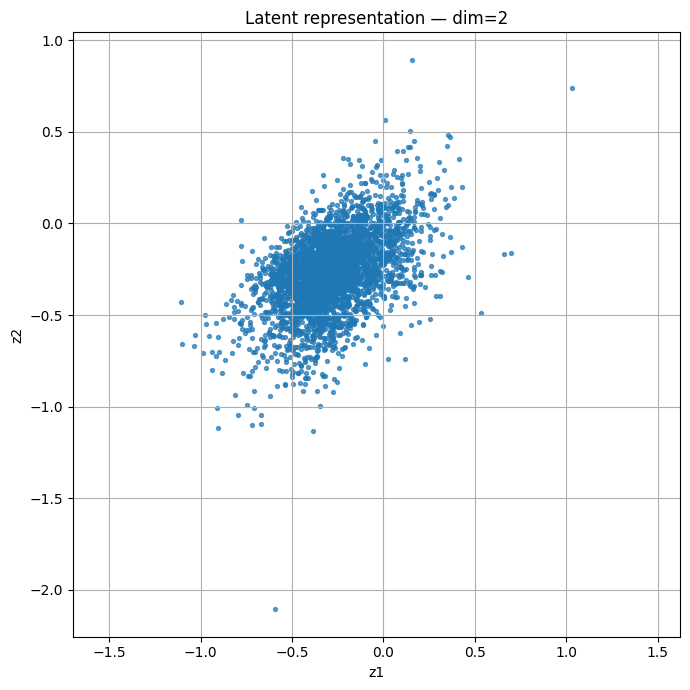

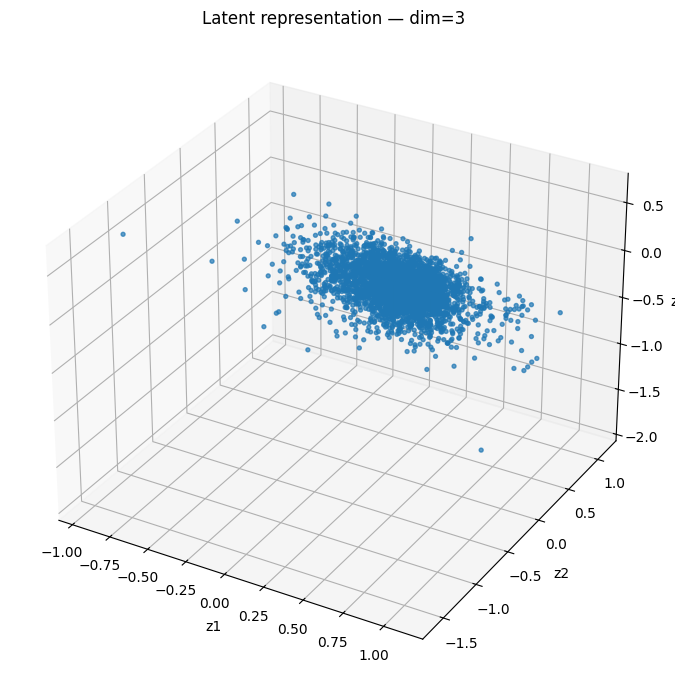

In [36]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 2, 3]
N_BINS = 40
BATCH_SIZE = 32768


# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        positions=positions
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

baseline_curve = pd.read_csv(
        "baselines/geometry_mlp_probability_vs_distance.csv",
        index_col=0
    )

baseline_centers = np.array([
pd.Interval(left=float(s.split(",")[0][1:]),
            right=float(s.split(",")[1][:-1])).mid
for s in baseline_curve.index
])

plt.plot(
    baseline_curve["bin_center"],
    baseline_curve["predicted_prob"],
    marker="o",
    linestyle="--",
    label="Geometry MLP baseline"
)


plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="x",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

Latent columns: ['z1']
Biological columns: ['pt_position_x', 'pt_position_y', 'pt_position_z', 'pref_ori_fit']


In [38]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

=== Spearman correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit
z1       0.020119       0.050248      -0.041732       0.03596

=== Pearson correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit
z1       0.010766        0.03652      -0.050132      0.045212


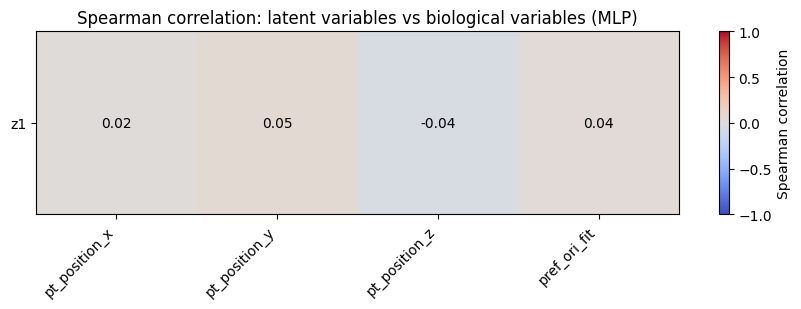

In [39]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (MLP)")
plt.tight_layout()
plt.show()

=== Strongest correlations ===
z1  pt_position_y    0.050248
    pt_position_z    0.041732
    pref_ori_fit     0.035960
    pt_position_x    0.020119
dtype: float64


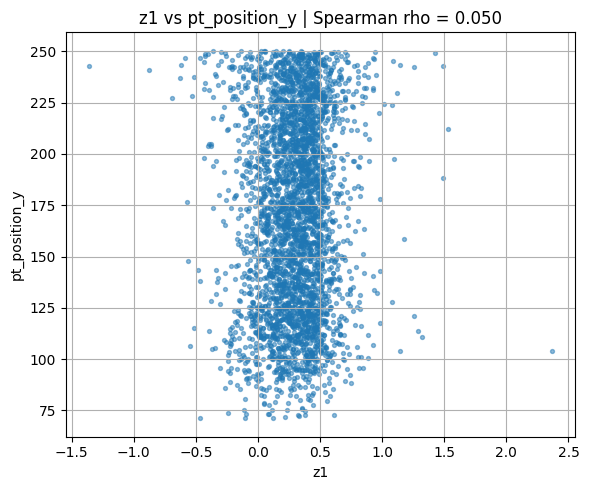

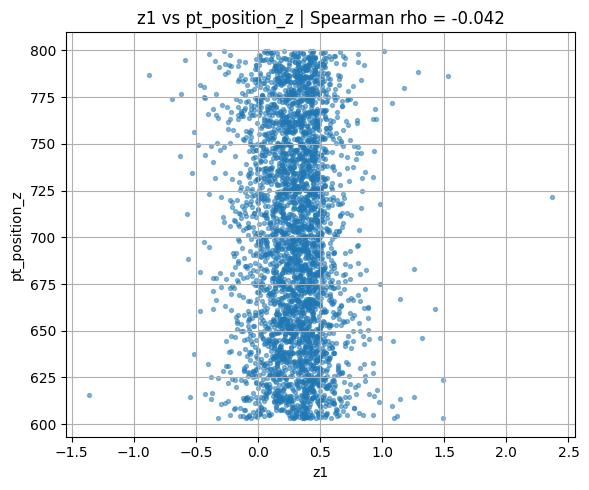

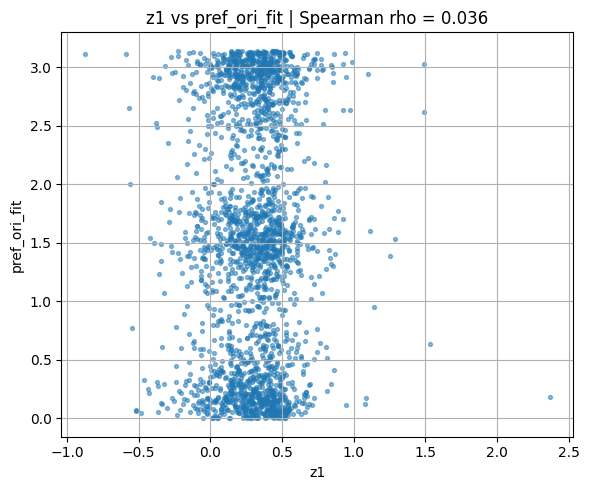

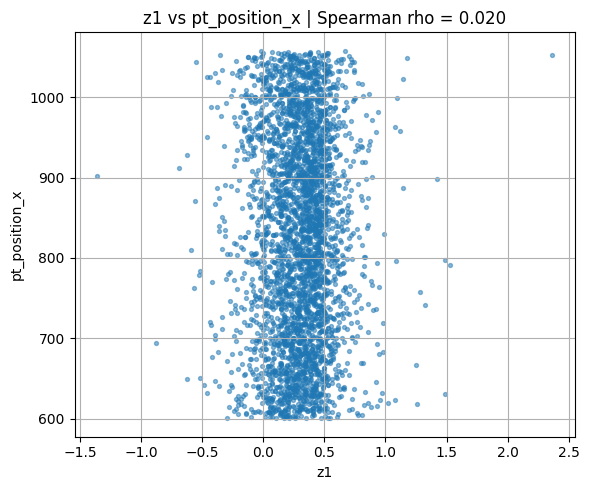

In [40]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [41]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

PCA skipped: latent dimension < 2


In [42]:
import pickle
import h5py
import pandas as pd

with open("MICrONS\\readout_info\\foundation_model.pkl", "rb") as f:
    foundation = pickle.load(f)

with open("MICrONS\\readout_info\\hierarchical_model.pkl", "rb") as f:
    hierarchical = pickle.load(f)

h5 = h5py.File("MICrONS\\microns.h5", "r")
print(h5.keys())

<KeysViewHDF5 ['brain_areas', 'sessions', 'types', 'videos']>


In [43]:
def explore_h5(g, prefix=""):
    for k in g.keys():
        item = g[k]
        path = f"{prefix}/{k}"
        print(path, type(item), getattr(item, "shape", ""))
        if isinstance(item, h5py.Group):
            explore_h5(item, path)

explore_h5(h5)

/brain_areas <class 'h5py._hl.group.Group'> 
/brain_areas/AL <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7 <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices/AL <class 'h5py._hl.dataset.Dataset'> (387,)
/brain_areas/AL/4_7/meta/area_indices/LM <class 'h5py._hl.dataset.Dataset'> (983,)
/brain_areas/AL/4_7/meta/area_indices/RL <class 'h5py._hl.dataset.Dataset'> (811,)
/brain_areas/AL/4_7/meta/area_indices/V1 <class 'h5py._hl.dataset.Dataset'> (5312,)
/brain_areas/AL/4_7/meta/brain_areas <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/meta/condition_hashes <class 'h5py._hl.dataset.Dataset'> (464,)
/brain_areas/AL/4_7/meta/coordinates <class 'h5py._hl.dataset.Dataset'> (7493, 3)
/brain_areas/AL/4_7/meta/unit_ids <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/trials <class 'h5py._hl.group.Group'> 
/brain_areas/

In [44]:
import os
import numpy as np
import torch
from sklearn.metrics import roc_auc_score


# ============================================================
# Bootstrap AUC using precomputed common indices
# ============================================================

def bootstrap_auc(y_true, y_score, bootstrap_indices):

    n_boot = len(bootstrap_indices)
    aucs = np.empty(n_boot, dtype=np.float32)

    base_auc = roc_auc_score(y_true, y_score)

    for b, idx in enumerate(bootstrap_indices):

        if b % 50 == 0:
            print(f"  bootstrap {b}/{n_boot}", flush=True)

        aucs[b] = roc_auc_score(
            y_true[idx],
            y_score[idx]
        )

    return (
        base_auc,
        np.percentile(aucs, 2.5),
        np.percentile(aucs, 97.5),
        aucs.std(),
        aucs
    )


# ============================================================
# Config
# ============================================================

N_BOOT = 200
SEED = 42

results_bootstrap = []

# Keep bootstrap AUC distributions for later paired comparisons
bootstrap_aucs_by_dim = {}

# These will be created only once, after loading the first model
bootstrap_indices = None
reference_y_true = None


# ============================================================
# Loop over dimensions
# ============================================================

for dim in range(1, 7):

    print(f"\nLoading dim={dim}", flush=True)

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        positions=positions
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    y_true = []
    y_score = []

    with torch.no_grad():

        for pre_b, post_b, y_b in test_loader:

            pred = model(
                pre_b.to(DEVICE),
                post_b.to(DEVICE)
            )

            y_true.append(
                y_b.detach().cpu().numpy()
            )

            y_score.append(
                pred.detach().cpu().numpy()
            )

    y_true = np.concatenate(y_true)
    y_score = np.concatenate(y_score)

    print("  predictions done", flush=True)
    print(
        "  n_test:",
        len(y_true),
        "positive rate:",
        y_true.mean(),
        flush=True
    )

    # ========================================================
    # Create common bootstrap indices only once
    # ========================================================

    if bootstrap_indices is None:

        reference_y_true = y_true.copy()

        rng = np.random.default_rng(SEED)

        n = len(y_true)

        bootstrap_indices = [
            rng.integers(
                low=0,
                high=n,
                size=n
            )
            for _ in range(N_BOOT)
        ]

        print(
            "  Common bootstrap samples created",
            flush=True
        )

    else:

        # Safety check:
        # same test labels and same order for every dimension
        if not np.array_equal(
            y_true,
            reference_y_true
        ):
            raise ValueError(
                f"Test set differs for dim={dim}. "
                "Paired bootstrap comparison is invalid."
            )

    # ========================================================
    # Bootstrap with the SAME samples for every dimension
    # ========================================================

    auc, ci_low, ci_high, std, auc_samples = bootstrap_auc(
        y_true,
        y_score,
        bootstrap_indices
    )

    bootstrap_aucs_by_dim[dim] = auc_samples

    print(
        f"dim={dim:02d} | "
        f"AUC={auc:.4f} | "
        f"95% CI=[{ci_low:.4f}, {ci_high:.4f}]",
        flush=True
    )

    results_bootstrap.append({
        "dim": dim,
        "auc": float(auc),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "std": float(std),
    })


# ============================================================
# Summary
# ============================================================

print("\nBootstrap summary")

for r in results_bootstrap:

    print(
        f"dim={r['dim']:2d} | "
        f"AUC={r['auc']:.4f} | "
        f"95% CI=[{r['ci_low']:.4f}, "
        f"{r['ci_high']:.4f}]"
    )


Loading dim=1
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  Common bootstrap samples created
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=01 | AUC=0.9092 | 95% CI=[0.9058, 0.9117]

Loading dim=2
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=02 | AUC=0.9121 | 95% CI=[0.9090, 0.9144]

Loading dim=3
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=03 | AUC=0.9155 | 95% CI=[0.9126, 0.9179]

Loading dim=4
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=04 | AUC=0.9159 | 95% CI=[0.9131, 0.9181]

Loading dim=5
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/

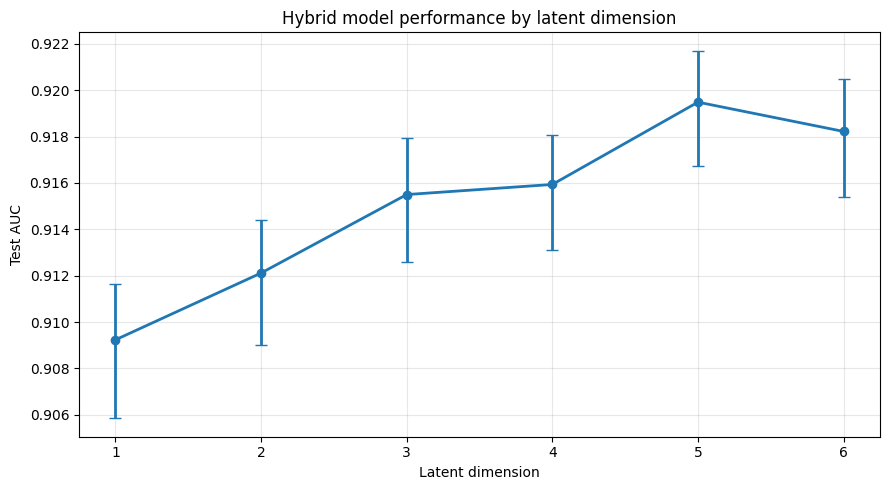

In [45]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. AUC selon le nombre de dimensions latentes
# ============================================================

dims = np.array([r["dim"] for r in results_bootstrap])
aucs = np.array([r["auc"] for r in results_bootstrap])
ci_low = np.array([r["ci_low"] for r in results_bootstrap])
ci_high = np.array([r["ci_high"] for r in results_bootstrap])

yerr = np.vstack([
    aucs - ci_low,
    ci_high - aucs
])

plt.figure(figsize=(9, 5))

plt.errorbar(
    dims,
    aucs,
    yerr=yerr,
    marker="o",
    linewidth=2,
    capsize=4
)

plt.xticks(dims)
plt.xlabel("Latent dimension")
plt.ylabel("Test AUC")
plt.title("Hybrid model performance by latent dimension")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

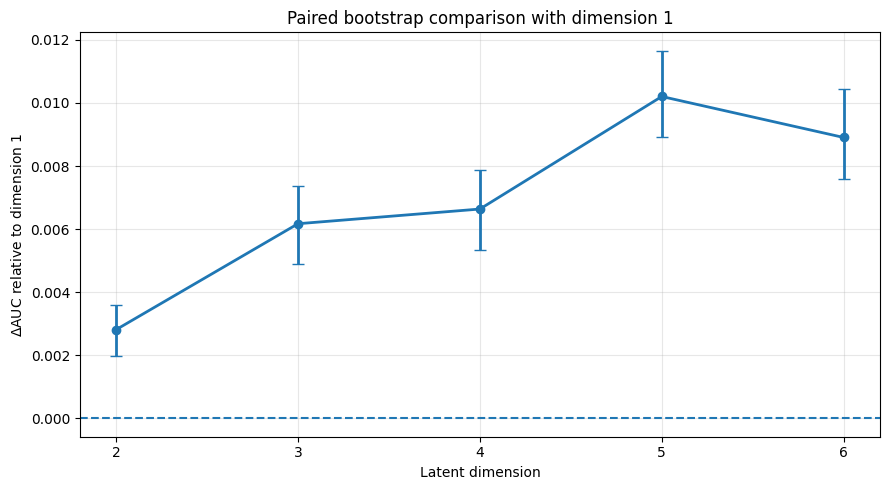

In [46]:
# ============================================================
# 2. Paired ΔAUC relative to a reference dimension
# ============================================================

REFERENCE_DIM = 1

reference_aucs = bootstrap_aucs_by_dim[REFERENCE_DIM]

comparison_dims = [
    dim for dim in sorted(bootstrap_aucs_by_dim)
    if dim != REFERENCE_DIM
]

mean_deltas = []
delta_ci_low = []
delta_ci_high = []

for dim in comparison_dims:

    # Same bootstrap sample for both dimensions
    delta = (
        bootstrap_aucs_by_dim[dim]
        - reference_aucs
    )

    mean_deltas.append(delta.mean())
    delta_ci_low.append(np.percentile(delta, 2.5))
    delta_ci_high.append(np.percentile(delta, 97.5))

mean_deltas = np.array(mean_deltas)
delta_ci_low = np.array(delta_ci_low)
delta_ci_high = np.array(delta_ci_high)

yerr = np.vstack([
    mean_deltas - delta_ci_low,
    delta_ci_high - mean_deltas
])

plt.figure(figsize=(9, 5))

plt.axhline(
    0,
    linestyle="--",
    linewidth=1.5
)

plt.errorbar(
    comparison_dims,
    mean_deltas,
    yerr=yerr,
    marker="o",
    linewidth=2,
    capsize=4
)

plt.xticks(comparison_dims)
plt.xlabel("Latent dimension")
plt.ylabel(rf"$\Delta$AUC relative to dimension {REFERENCE_DIM}")
plt.title(
    rf"Paired bootstrap comparison with dimension {REFERENCE_DIM}"
)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

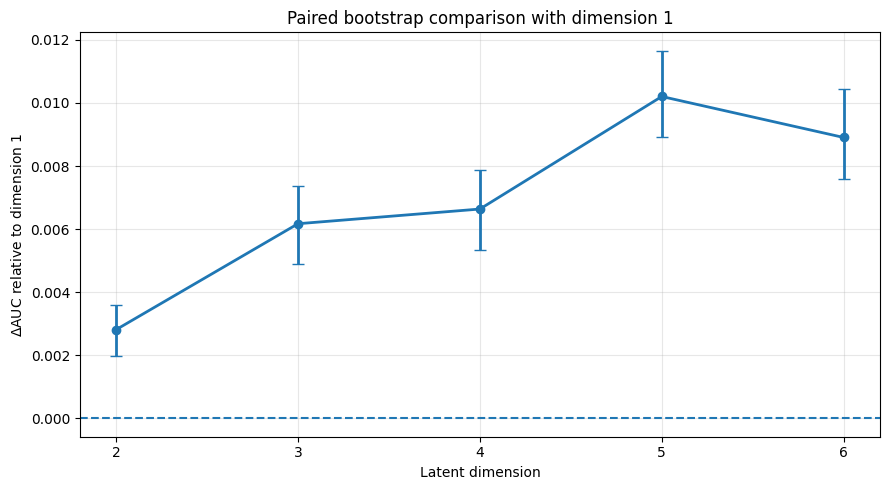

In [47]:
# ============================================================
# 2. Paired ΔAUC relative to a reference dimension
# ============================================================

REFERENCE_DIM = 1

reference_aucs = bootstrap_aucs_by_dim[REFERENCE_DIM]

comparison_dims = [
    dim for dim in sorted(bootstrap_aucs_by_dim)
    if dim != REFERENCE_DIM
]

mean_deltas = []
delta_ci_low = []
delta_ci_high = []

for dim in comparison_dims:

    # Same bootstrap sample for both dimensions
    delta = (
        bootstrap_aucs_by_dim[dim]
        - reference_aucs
    )

    mean_deltas.append(delta.mean())
    delta_ci_low.append(np.percentile(delta, 2.5))
    delta_ci_high.append(np.percentile(delta, 97.5))

mean_deltas = np.array(mean_deltas)
delta_ci_low = np.array(delta_ci_low)
delta_ci_high = np.array(delta_ci_high)

yerr = np.vstack([
    mean_deltas - delta_ci_low,
    delta_ci_high - mean_deltas
])

plt.figure(figsize=(9, 5))

plt.axhline(
    0,
    linestyle="--",
    linewidth=1.5
)

plt.errorbar(
    comparison_dims,
    mean_deltas,
    yerr=yerr,
    marker="o",
    linewidth=2,
    capsize=4
)

plt.xticks(comparison_dims)
plt.xlabel("Latent dimension")
plt.ylabel(rf"$\Delta$AUC relative to dimension {REFERENCE_DIM}")
plt.title(
    rf"Paired bootstrap comparison with dimension {REFERENCE_DIM}"
)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
import os
import numpy as np
import torch
from sklearn.metrics import roc_auc_score

def bootstrap_auc(y_true, y_score, n_boot=200, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    aucs = np.empty(n_boot, dtype=np.float32)

    base_auc = roc_auc_score(y_true, y_score)

    for b in range(n_boot):
        if b % 50 == 0:
            print(f"  bootstrap {b}/{n_boot}", flush=True)

        idx = rng.integers(0, n, size=n)
        aucs[b] = roc_auc_score(y_true[idx], y_score[idx])

    return (
        base_auc,
        np.percentile(aucs, 2.5),
        np.percentile(aucs, 97.5),
        aucs.std()
    )


results_bootstrap = []

for dim in range(1, 16):
    print(f"\nLoading dim={dim}", flush=True)

    ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        positions=positions
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    y_true = []
    y_score = []

    with torch.no_grad():
        for pre_b, post_b, y_b in test_loader:
            pred = model(
                pre_b.to(DEVICE),
                post_b.to(DEVICE)
            )

            y_true.append(y_b.detach().cpu().numpy())
            y_score.append(pred.detach().cpu().numpy())

    y_true = np.concatenate(y_true)
    y_score = np.concatenate(y_score)

    print("  predictions done", flush=True)
    print("  n_test:", len(y_true), "positive rate:", y_true.mean(), flush=True)

    auc, ci_low, ci_high, std = bootstrap_auc(
        y_true,
        y_score,
        n_boot=200,
        seed=42 + dim
    )

    print(
        f"dim={dim:02d} | AUC={auc:.4f} | "
        f"95% CI=[{ci_low:.4f}, {ci_high:.4f}]",
        flush=True
    )

    results_bootstrap.append({
        "dim": dim,
        "auc": float(auc),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "std": float(std),
    })

print("\nBootstrap summary")
for r in results_bootstrap:
    print(
        f"dim={r['dim']:2d} | "
        f"AUC={r['auc']:.4f} | "
        f"95% CI=[{r['ci_low']:.4f}, {r['ci_high']:.4f}]"
    )


Loading dim=1
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=01 | AUC=0.9092 | 95% CI=[0.9070, 0.9124]

Loading dim=2
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=02 | AUC=0.9121 | 95% CI=[0.9094, 0.9153]

Loading dim=3
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=03 | AUC=0.9155 | 95% CI=[0.9128, 0.9183]

Loading dim=4
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=04 | AUC=0.9159 | 95% CI=[0.9131, 0.9181]

Loading dim=5
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=05 | AUC=0.9195 | 95% CI=[0

FileNotFoundError: [Errno 2] No such file or directory: 'checkpoints_embedding_MLP_hybrid_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple\\best_dim_7.pt'